# Used Car Price Analysis

## Project Overview

This is a self-study data analysis project developed to practice Python-based data analysis. The project explores a used-car dataset to understand its structure, assess data quality, clean duplicate records, and investigate patterns in vehicle selling prices.

The analysis focuses on the relationship between selling price and vehicle characteristics such as manufacturing year, kilometres driven, fuel type, transmission, seller type, and ownership category.

## Objectives

- Understand the structure and quality of the dataset.
- Inspect numerical and categorical features.
- Identify missing values and exact duplicate records.
- Clean and validate the dataset.
- Explore the distribution of used-car selling prices.
- Investigate relationships between selling price, manufacturing year, and kilometres driven.
- Examine the composition of fuel, transmission, seller, and owner categories.
- Summarize findings and acknowledge the limitations of the analysis.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Project Scope

This project focuses on data cleaning, descriptive statistics, exploratory data analysis (EDA), and visualization. It does not include a machine-learning model.

## Dataset

The dataset contains information about used cars, including their names, manufacturing years, selling prices, kilometres driven, fuel types, seller types, transmission types, and ownership categories.

## Note

This project was completed as a self-study exercise with AI assistance for learning, code guidance, and documentation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style for charts
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Loading and Inspection

In this section, the CSV dataset is loaded into a Pandas DataFrame. Initial inspection helps us understand the number of records, available columns, data types, and the structure of the dataset before performing any cleaning.

In [ ]:
df = pd.read_csv("/content/car_data.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [ ]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

First five rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


Last five rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4340
Number of columns: 8


In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [ ]:
print("Missing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Total missing values: 0


In [ ]:
print("Numerical descriptive statistics:")
display(df.describe().T)

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
year,4340.0,2013.090783,4.215344,1992.0,2011.00,2014.0,2016.0,2020.0
selling_price,4340.0,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,66215.777419,46644.102194,1.0,35000.00,60000.0,90000.0,806599.0


In [ ]:
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(sorted(df[column].astype(str).unique()))


Unique values in fuel:
['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']

Unique values in seller_type:
['Dealer', 'Individual', 'Trustmark Dealer']

Unique values in transmission:
['Automatic', 'Manual']

Unique values in owner:
['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']


In [ ]:
for column in categorical_columns:
    print(f"\nCategory counts for {column}:")
    display(df[column].value_counts())


Category counts for fuel:


,count
fuel,
Diesel,2153
Petrol,2123
CNG,40
LPG,23
Electric,1



Category counts for seller_type:


,count
seller_type,
Individual,3244
Dealer,994
Trustmark Dealer,102



Category counts for transmission:


,count
transmission,
Manual,3892
Automatic,448



Category counts for owner:


,count
owner,
First Owner,2832
Second Owner,1106
Third Owner,304
Fourth & Above Owner,81
Test Drive Car,17


## 2. Data Cleaning and Validation

Data cleaning helps identify duplicate records and potential data-quality issues before analysis. The original DataFrame is preserved, while a separate cleaned DataFrame is created for subsequent analysis.

Exact duplicate rows are investigated and removed under the assumption that identical records are redundant. Since the dataset does not provide a unique vehicle or listing identifier, this assumption is documented as a limitation.

Unusual prices and mileage values are inspected rather than automatically deleted, because extreme values can represent legitimate used-car listings.

In [ ]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Percentage of duplicate rows: {duplicate_percentage:.2f}%")

Exact duplicate rows: 763
Percentage of duplicate rows: 17.58%


In [ ]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in exact duplicates:", len(duplicate_rows))

display(
    duplicate_rows.sort_values(
        ["name", "year", "selling_price"]
    ).head(15)
)

Rows involved in exact duplicates: 1289


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3912,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
4016,Ambassador CLASSIC 1500 DSL AC,2005,120000,50000,Diesel,Individual,Manual,Second Owner
99,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
2578,Audi A4 2.0 TDI 177 Bhp Premium Plus,2013,1150000,53000,Diesel,Dealer,Automatic,First Owner
554,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
573,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
592,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
611,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
899,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner
918,Audi A4 3.0 TDI Quattro,2013,1580000,86000,Diesel,Dealer,Automatic,First Owner


In [ ]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Original rows: 4340
Rows after removing exact duplicates: 3577
Rows removed: 763
Remaining exact duplicates: 0

Cleaned dataset shape: (3577, 8)


In [ ]:
print("Lowest-priced cars:")

display(
    df_clean.nsmallest(10, "selling_price")[
        ["name", "year", "selling_price", "km_driven"]
    ]
)

Lowest-priced cars:


,name,year,selling_price,km_driven
2257,Ford Ikon 1.6 ZXI NXt,2005,20000,25000
2132,Ford Ikon 1.4 ZXi,2000,22000,42743
2098,Maruti 800 EX,2004,30000,60000
1659,Tata Nano LX SE,2012,35000,35000
2410,Tata Nano Std BSII,2009,35000,50000
2696,OpelCorsa 1.4 GL,2002,35000,100000
3547,Maruti 800 Std,2004,37500,90000
124,Maruti 800 Std,1998,40000,40000
798,Tata Nano Std,2011,40000,19000
1207,Maruti 800 EX,2001,40000,30000


In [ ]:
print("Highest-priced cars:")

display(
    df_clean.nlargest(10, "selling_price")[
        ["name", "year", "selling_price", "km_driven"]
    ]
)

Highest-priced cars:


,name,year,selling_price,km_driven
3257,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000
76,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500
3341,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350
540,BMW X5 xDrive 30d xLine,2019,4950000,30000
2881,BMW 5 Series 520d Luxury Line,2018,4800000,9422
3267,BMW 5 Series 520d Luxury Line,2019,4800000,12999
846,Audi A5 Sportback,2020,4700000,1500
88,Mercedes-Benz E-Class Exclusive E 200 BSIV,2018,4500000,9800
3385,Volvo XC 90 D5 Inscription BSIV,2017,4500000,80000
524,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,2014,4400000,100000


In [ ]:
print("Highest-kilometre cars:")

display(
    df_clean.nlargest(10, "km_driven")[
        ["name", "year", "selling_price", "km_driven"]
    ]
)

Highest-kilometre cars:


,name,year,selling_price,km_driven
1101,Maruti Swift VXI BSIII,2009,250000,806599
510,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000
3091,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000
56,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000
2057,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000
3123,Toyota Innova 2.5 GX 8 STR BSIV,2009,420000,347089
1508,Volkswagen Jetta 2.0 TDI Comfortline,2011,350000,312000
962,Tata Indica DLS,2006,85000,300000
1497,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,2006,229999,300000
3279,Tata Indica GLS BS IV,2010,90000,300000


In [ ]:
print("Negative selling prices:",
      (df_clean["selling_price"] < 0).sum())

print("Zero selling prices:",
      (df_clean["selling_price"] == 0).sum())

print("Negative kilometres:",
      (df_clean["km_driven"] < 0).sum())

print("Zero kilometres:",
      (df_clean["km_driven"] == 0).sum())

print("Years before 1990:",
      (df_clean["year"] < 1990).sum())

print("Years after 2026:",
      (df_clean["year"] > 2026).sum())

Negative selling prices: 0
Zero selling prices: 0
Negative kilometres: 0
Zero kilometres: 0
Years before 1990: 0
Years after 2026: 0


In [ ]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
display(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nNumerical summary:")
display(df_clean.describe().T)

Dataset shape: (3577, 8)

Missing values:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Duplicate rows: 0

Data types:
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
year,3577.0,2012.962538,4.251759,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3577.0,473912.542074,509301.809816,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3577.0,69250.545709,47579.940016,1.0,36000.0,60000.0,90000.0,806599.0


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the distribution of the data, identify patterns, and investigate relationships between variables.

This section examines selling-price distributions, the relationship between kilometres driven and selling price, changes in median selling prices across manufacturing years, and the composition of categorical features.

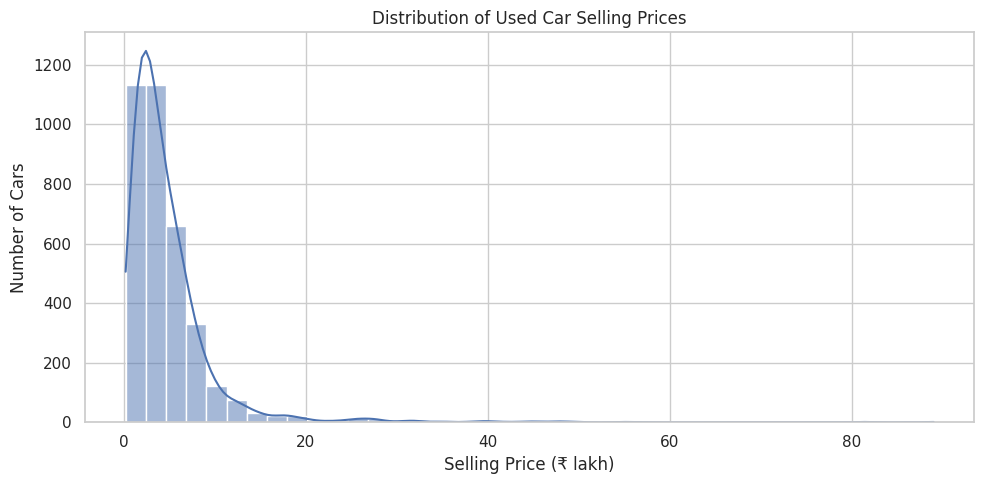

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x=df_clean["selling_price"] / 100000,
    bins=40,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹ lakh)")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

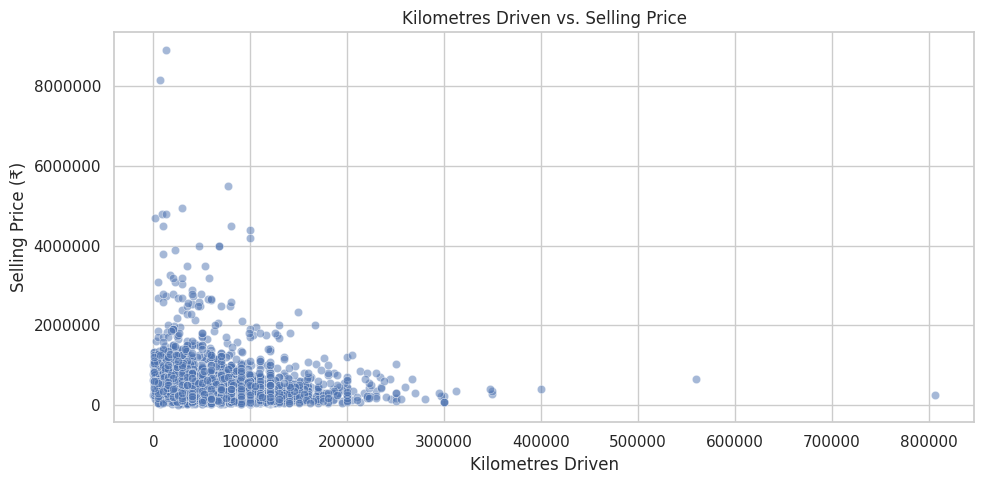

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometres Driven vs. Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")

plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

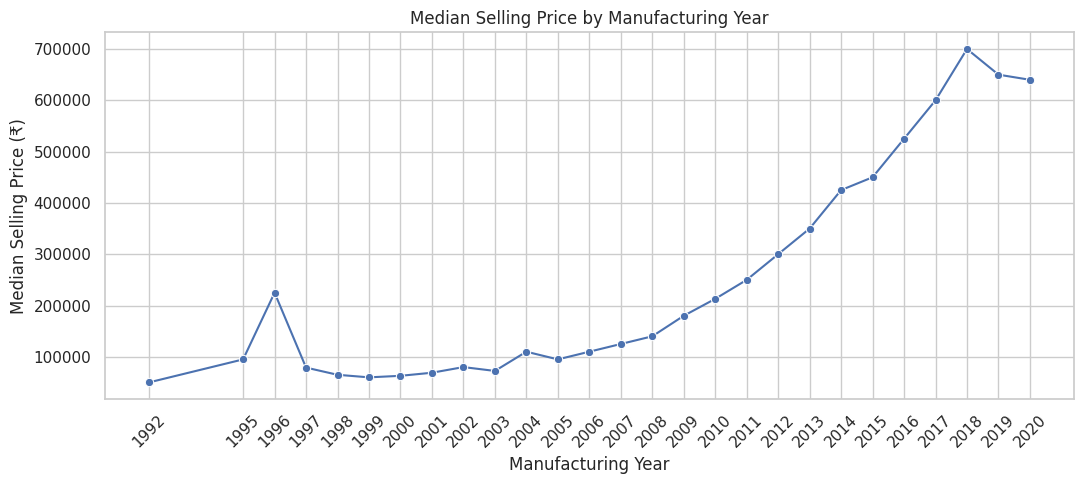

In [ ]:
yearly_prices = (
    df_clean.groupby("year")["selling_price"]
    .median()
    .sort_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    x=yearly_prices.index,
    y=yearly_prices.values,
    marker="o"
)

plt.title("Median Selling Price by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Median Selling Price (₹)")

plt.xticks(sorted(df_clean["year"].unique()), rotation=45)
plt.ticklabel_format(axis="y", style="plain")

plt.tight_layout()
plt.show()

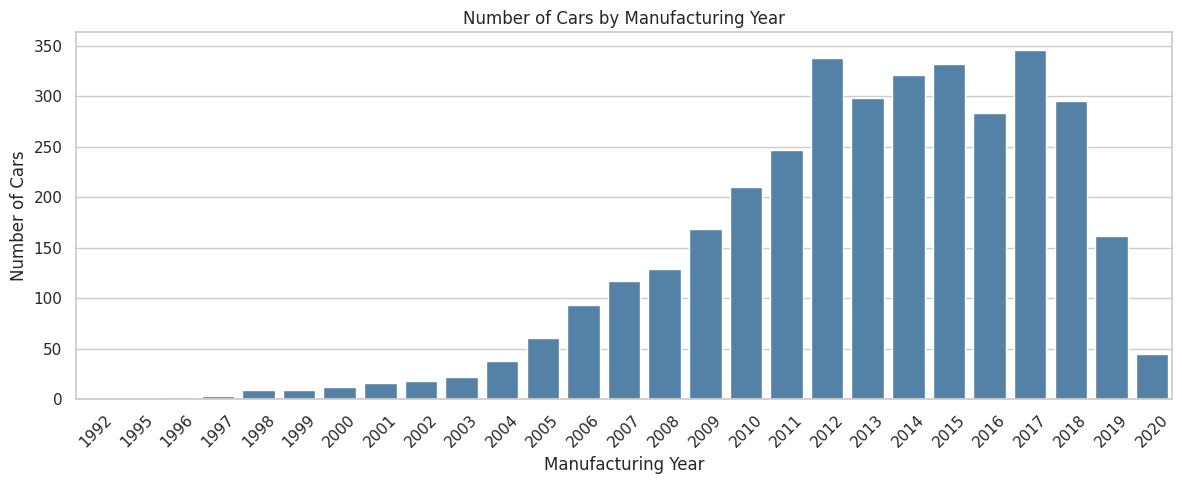

In [ ]:
year_counts = (
    df_clean["year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values,
    color="steelblue"
)

plt.title("Number of Cars by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print("Cars manufactured in 1996:",
      df_clean["year"].eq(1996).sum())

display(
    df_clean.loc[
        df_clean["year"] == 1996,
        [
            "name",
            "year",
            "selling_price",
            "km_driven",
            "fuel",
            "transmission",
            "owner"
        ]
    ]
)

Cars manufactured in 1996: 2


,name,year,selling_price,km_driven,fuel,transmission,owner
48,Mahindra Jeep CL 500 MDI,1996,250000,35000,Diesel,Manual,Second Owner
2506,Mahindra Jeep MM 540,1996,200000,60000,Diesel,Manual,First Owner


In [ ]:
categorical_columns = [
    "fuel",
    "transmission",
    "seller_type",
    "owner"
]

for column in categorical_columns:
    print(f"\nSelling price analysis by {column}:")

    summary = (
        df_clean.groupby(column)["selling_price"]
        .agg(
            number_of_cars="count",
            median_price="median",
            average_price="mean"
        )
        .sort_values("median_price", ascending=False)
    )

    display(summary.round(2))


Selling price analysis by fuel:


,number_of_cars,median_price,average_price
fuel,,,
Diesel,1800,475000.0,614001.07
Electric,1,310000.0,310000.00
Petrol,1717,260000.0,335344.34
CNG,37,229999.0,273162.08
LPG,22,180000.0,171818.14



Selling price analysis by transmission:


,number_of_cars,median_price,average_price
transmission,,,
Automatic,312,855000.0,1274955.11
Manual,3265,325000.0,397365.75



Selling price analysis by seller_type:


,number_of_cars,median_price,average_price
seller_type,,,
Trustmark Dealer,33,750000.0,822272.73
Dealer,712,484999.0,652699.39
Individual,2832,303500.0,424904.02



Selling price analysis by owner:


,number_of_cars,median_price,average_price
owner,,,
Test Drive Car,17,894999.0,954293.94
First Owner,2218,450000.0,565385.45
Second Owner,978,267000.0,341954.14
Third Owner,289,190000.0,266142.21
Fourth & Above Owner,75,138000.0,181213.29


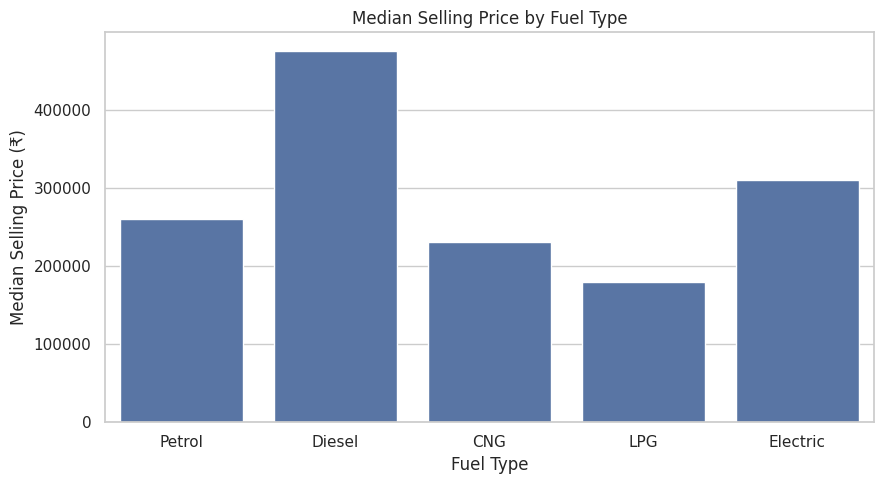

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="fuel",
    y="selling_price",
    estimator="median",
    errorbar=None
)

plt.title("Median Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Median Selling Price (₹)")

plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

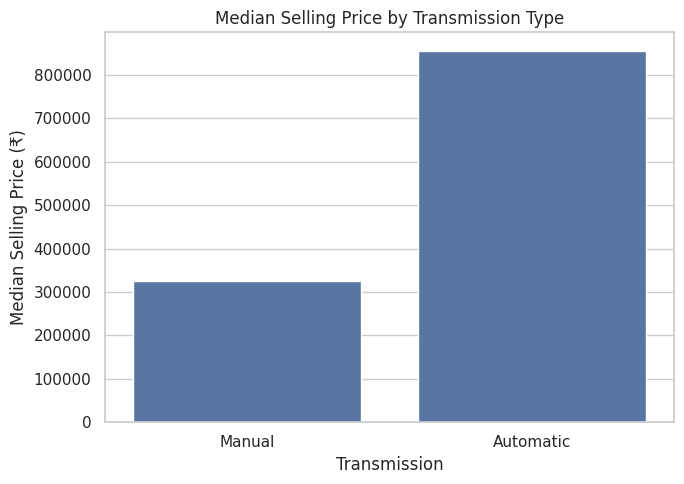

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df_clean,
    x="transmission",
    y="selling_price",
    estimator="median",
    errorbar=None
)

plt.title("Median Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Median Selling Price (₹)")

plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [ ]:
mileage_correlation = (
    df_clean["km_driven"].corr(df_clean["selling_price"])
)

year_correlation = (
    df_clean["year"].corr(df_clean["selling_price"])
)

print(
    "Correlation between mileage and price:",
    round(mileage_correlation, 3)
)

print(
    "Correlation between manufacturing year and price:",
    round(year_correlation, 3)
)

Correlation between mileage and price: -0.187
Correlation between manufacturing year and price: 0.424


## 4. Key Findings

### 1. Dataset Quality

The original dataset contained 4,340 rows and eight columns. No missing values were found in the original dataset.

### 2. Duplicate Records

A total of 763 exact duplicate rows were identified and removed, leaving 3,577 rows for analysis. This cleaning decision assumes identical rows are redundant because the dataset does not contain a unique listing identifier.

### 3. Selling-Price Distribution

The cleaned dataset had a mean selling price of approximately ₹473,913 and a median of ₹350,000. The higher mean suggests that high-priced vehicles pull the average upward.

### 4. Manufacturing Year

The median selling-price chart generally showed higher prices for newer manufacturing years, although the trend fluctuated. Only two cars were recorded for 1996, so its median price should not be treated as representative of that manufacturing year.

### 5. Kilometres Driven

The scatterplot suggested that cars with higher mileage generally have lower selling prices. However, mileage is only one of several factors that may influence used-car prices.

### 6. Categorical Features

Diesel and petrol cars made up most of the cleaned dataset. Manual transmission and individual sellers were also strongly represented. The dataset contained only one electric car, limiting meaningful generalizations about that category.

### 7. Unusual Values

Some cars had exceptionally high selling prices or mileage. These observations were investigated and retained because the available evidence did not establish that they were data errors.

## 5. Limitations

- Exact duplicate rows could not be confirmed as duplicate real-world listings because the dataset has no unique listing identifier.
- Vehicle condition, accident history, geographic location and service history were not available in the examined columns.
- Some manufacturing years and categories contained very few observations.
- Relationships observed in charts do not establish causation.
- This project focuses on data analysis and does not include a machine-learning prediction model.

## 6. Conclusion

This self-study project provided practical experience with Python-based data loading, cleaning, descriptive statistics, and exploratory data analysis.

The analysis highlighted the importance of investigating duplicate records, interpreting skewed distributions, examining relationships between vehicle characteristics and selling prices, and acknowledging sample-size limitations.

The project serves as a foundation for further study in data analysis and future machine-learning projects.

In [ ]:
print("FINAL PROJECT VALIDATION")
print("-" * 35)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

print("\nProject validation completed.")

FINAL PROJECT VALIDATION
-----------------------------------
Original dataset shape: (4340, 8)
Cleaned dataset shape: (3577, 8)
Rows removed: 763
Remaining exact duplicates: 0
Missing values: 0

Project validation completed.
